# Task 4: Explainable Fuzzy Classifier
## This notebook builds a human-interpretable fuzzy classifier using handcrafted geometric features extracted from facial landmarks. The key idea is that fuzzy rules like "IF smile is ver high THEN happy" are intuitive an explainable to humans.

### First, we load the KDEF metadata and split the data, ensuring we only use frontal poses (as required).

In [ ]:
import os, pickle
from pathlib import Path
import cv2
import dlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define mappings from KDEF codes to full names
EMOTIONS = {"AF":"afraid","AN":"angry","DI":"disgust","HA":"happy",
            "NE":"neutral","SA":"sad","SU":"surprise"}
POSES = {"FL":"full_left","HL":"half_left","S":"straight",
         "HR":"half_right","FR":"full_right"}

# Parse all KDEF image filenames to build a metadata table
records = []
for img_path in Path("data/KDEF_and_AKDEF/KDEF").rglob("*.JPG"):
    stem = img_path.stem
    # Extract emotion code and pose code from filename (e.g., "AF01S" -> emo=AF, pose=S)
    for code, name in EMOTIONS.items():
        if stem[4:].startswith(code):
            pose_code = stem[4+len(code):]
            if pose_code in POSES:
                records.append(dict(path=str(img_path), acquisition=stem[0],
                                    subject=stem[1:4], emotion=name,
                                    pose=POSES[pose_code]))
            break

df = pd.DataFrame(records)

# Load the subject-independent train/test split
split = pickle.load(open("auxFiles/kdef_subject_split.pkl", "rb"))
df["split"] = np.where(df.subject.isin(split["train_subjects"]), "train",
               np.where(df.subject.isin(split["test_subjects"]), "test", "none"))

# Filter for only frontal (straight) poses, as required
df = df[df.pose == "straight"].reset_index(drop=True)

print("Images:", len(df))
print(df.groupby(["split", "emotion"]).size().unstack())

Images: 980
emotion  afraid  angry  disgust  happy  neutral  sad  surprise
split                                                         
test         28     28       28     28       28   28        28
train       112    112      112    112      112  112       112


In [ ]:
# For testing purposes to to see if there were the data in the folder
from pathlib import Path
for p in sorted(Path("data").rglob("*"))[:30]:
    print(p)

data\KDEF_and_AKDEF
data\KDEF_and_AKDEF\AKDEF
data\KDEF_and_AKDEF\AKDEF\FAFFL.JPG
data\KDEF_and_AKDEF\AKDEF\FAFFR.JPG
data\KDEF_and_AKDEF\AKDEF\FAFHL.JPG
data\KDEF_and_AKDEF\AKDEF\FAFS.JPG
data\KDEF_and_AKDEF\AKDEF\FAHR.JPG
data\KDEF_and_AKDEF\AKDEF\FANFL.JPG
data\KDEF_and_AKDEF\AKDEF\FANFR.JPG
data\KDEF_and_AKDEF\AKDEF\FANHL.JPG
data\KDEF_and_AKDEF\AKDEF\FANHR.JPG
data\KDEF_and_AKDEF\AKDEF\FANS.JPG
data\KDEF_and_AKDEF\AKDEF\FDIFL.JPG
data\KDEF_and_AKDEF\AKDEF\FDIFR.JPG
data\KDEF_and_AKDEF\AKDEF\FDIHL.JPG
data\KDEF_and_AKDEF\AKDEF\FDIHR.JPG
data\KDEF_and_AKDEF\AKDEF\FDIS.JPG
data\KDEF_and_AKDEF\AKDEF\FHAFL.JPG
data\KDEF_and_AKDEF\AKDEF\FHAFR.JPG
data\KDEF_and_AKDEF\AKDEF\FHAHL.JPG
data\KDEF_and_AKDEF\AKDEF\FHAHR.JPG
data\KDEF_and_AKDEF\AKDEF\FHAS.JPG
data\KDEF_and_AKDEF\AKDEF\FNEFL.JPG
data\KDEF_and_AKDEF\AKDEF\FNEFR.JPG
data\KDEF_and_AKDEF\AKDEF\FNEHL.JPG
data\KDEF_and_AKDEF\AKDEF\FNEHR.JPG
data\KDEF_and_AKDEF\AKDEF\FNES.JPG
data\KDEF_and_AKDEF\AKDEF\FSAFL.JPG
data\KDEF_and_AKDEF\AKDE

# --- Landmark Extraction using dlib & Compute Geometric Features ---
### We use dlib's 68-point landmark detector to extract facial landmarks for each image.
### These landmarks are then used to compute geometric features like mouth opening, smile ratio, etc.


Detection failures: 0 of 980
Empty DataFrame
Columns: [path, emotion]
Index: []
(980, 68, 2)


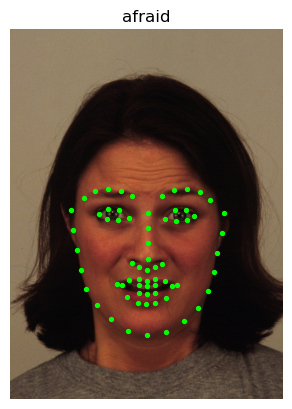

          mouth_opening  mouth_width  eye_opening  eyebrow_height  smile  \
emotion                                                                    
afraid            0.101        0.600        0.352           0.197  0.009   
angry             0.045        0.576        0.289           0.135  0.012   
disgust           0.089        0.630        0.222           0.157  0.023   
happy             0.127        0.789        0.250           0.206  0.090   
neutral           0.014        0.580        0.332           0.194 -0.007   
sad               0.019        0.599        0.300           0.196 -0.002   
surprise          0.142        0.541        0.404           0.232  0.005   

          brow_gap  
emotion             
afraid       0.242  
angry        0.207  
disgust      0.234  
happy        0.277  
neutral      0.251  
sad          0.231  
surprise     0.280  


C:\Users\ewenp\AppData\Local\Temp\ipykernel_56156\2142460194.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, showfliers=False)
C:\Users\ewenp\AppData\Local\Temp\ipykernel_56156\2142460194.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, showfliers=False)
C:\Users\ewenp\AppData\Local\Temp\ipykernel_56156\2142460194.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=order, showfliers=False)
C:\Users\ewenp\AppData\Local\Temp\ipykernel_56156\2142460194.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() ha

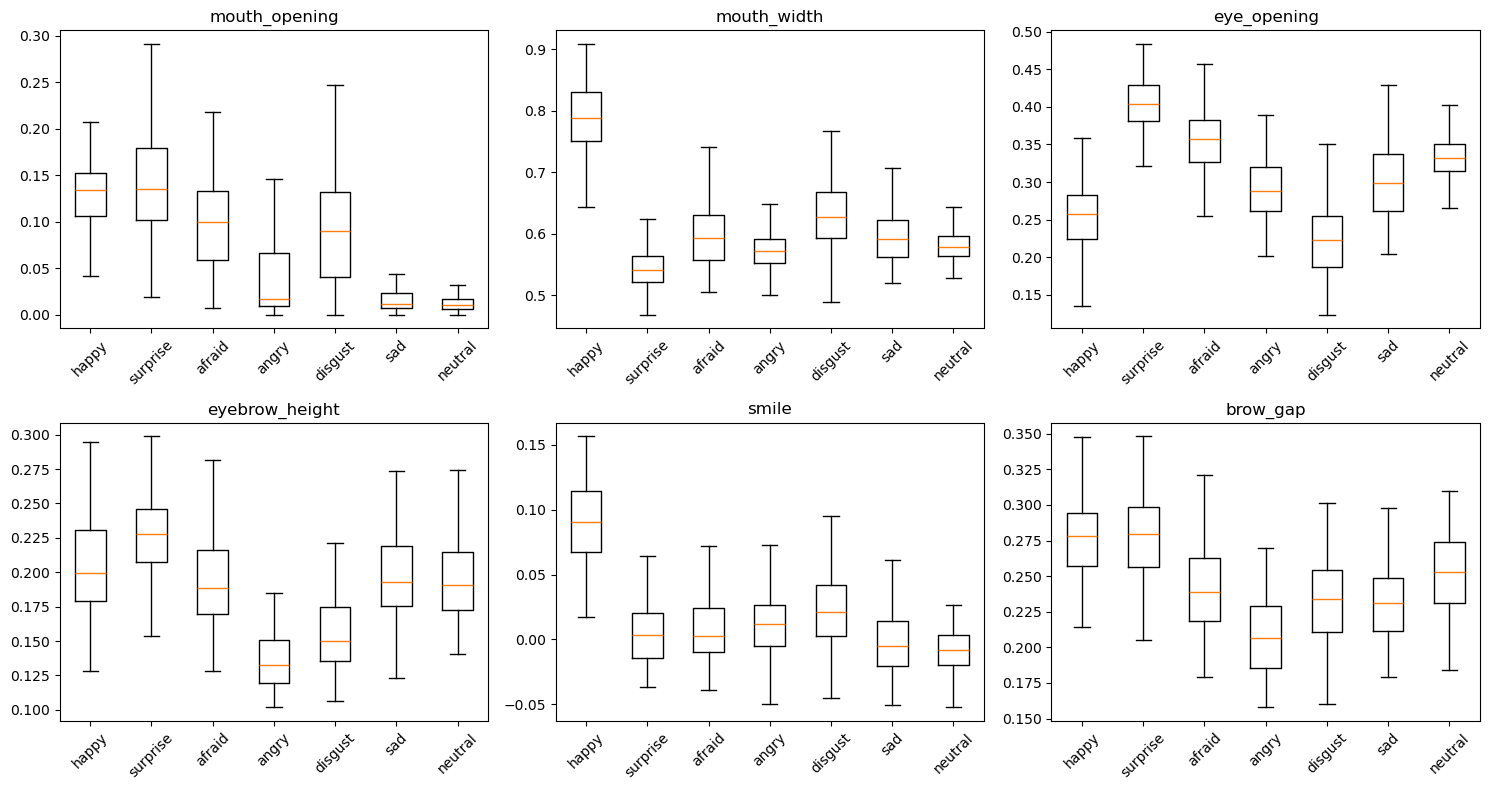

In [ ]:
detector  = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks_GTX.dat")

def get_landmarks(path):
    """
    Detect face and extract 68 landmark coordinates from an image.
    Returns None if face detection fails.
    """
    img = cv2.imread(path)
    if img is None:
        return None # Failed to Load image
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # Convert to grayscale for detection
    rects = detector(gray, 1) # Detect faces (1 = upsample for better detection)
    if len(rects) == 0:
        return None # No faces detected
    r = max(rects, key=lambda r: r.width() * r.height()) # Use the largest detected face
    shape = predictor(gray, r) # extract 68 landmarks
    return np.array([[p.x, p.y] for p in shape.parts()], dtype=np.float32)

# Helper function to compute distance between two landmarks
def d(P, i, j):
    return np.linalg.norm(P[i] - P[j])

def geometric_features(P):
    """
    Compute 6 interpretable geometric features from the 68 landmark coordinates.
    These features are designed to capture emotion-relevant facial movements:
    - mouth_opening: how open the mouth is
    - mouth_width: how wide the mouth is (smiling stretches it)
    - eye_opening: how wide the eyes are (surprise/fear = wide eyes)
    - eyebrow_height: raised eyebrows (surprise)
    - smile: whether mouth corners are raised (positive = smiling)
    - brow_gap: distance between eyebrows (furrowed brow = anger)
    
    All distances are normalized by inter-ocular distance (iod) to make them scale-invariant.
    """

    iod = d(P, 36, 45)  # Inter-ocular distance = distance between outer eye corners (normalizer)

    # Eye Aspect Ratio (EAR) - standard measure of eye openness
    ear_r = (d(P,37,41) + d(P,38,40)) / (2 * d(P,36,39)) # Right
    ear_l = (d(P,43,47) + d(P,44,46)) / (2 * d(P,42,45)) # Left

    # Mouth measurements
    mouth_mid_y = (P[62,1] + P[66,1]) / 2 # Vertical position of upper inner lip (landmarks 62, 66)
    corners_y   = (P[48,1] + P[54,1]) / 2 # Vertical position of mouth corners (landmarks 48, 54)
    
    return np.array([
         d(P,62,66) / iod,                      # mouth opening: distance between upper and lower inner lip
        d(P,48,54) / iod,                       # mouth width: distance between left and right mouth corners
        (ear_r + ear_l) / 2,                    # eye opening: average EAR of both eyes
        (d(P,19,37) + d(P,24,44)) / (2 * iod),  # eyebrow height: distance from eyebrow to eye
        (mouth_mid_y - corners_y) / iod,        # smile: positive = corners raised above lip (smiling)
        d(P,21,22) / iod,                       # brow gap: distance between inner eyebrows (furrowed = small)
    ])

# Extarct landmakrs for all images
lms = [get_landmarks(p) for p in df.path]
failed = [i for i, L in enumerate(lms) if L is None] # Track failed detections
print("Detection failures:", len(failed), "of", len(df))
print(df.loc[failed, ["path", "emotion"]].head(10)) # Show first 10 failures (if any)

# Keep only successfully processed images
ok = [i for i, L in enumerate(lms) if L is not None]
df_ok = df.loc[ok].reset_index(drop=True)
LM = np.stack([lms[i] for i in ok])          # Stack Landmarks into an array : shape (N, 68, 2)

# Save landmarks and metadata for reproducibility
np.save("auxFiles/kdef_landmarks_straight.npy", LM)
df_ok.to_csv("auxFiles/kdef_straight_meta.csv", index=False)
print(LM.shape)

# Sanity check: draw the landmarks on one image t verify extraction is correct.
i = 0
img = cv2.cvtColor(cv2.imread(df_ok.path[i]), cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.scatter(LM[i, :, 0], LM[i, :, 1], s=8, c="lime") # Green dots at each landmark of the face
plt.title(df_ok.emotion[i]); plt.axis("off"); plt.show()

# Geometrix features
FEATURES = ["mouth_opening", "mouth_width", "eye_opening",
            "eyebrow_height", "smile", "brow_gap"]

# Apply feature extraction to all landmarks sets
F = np.stack([geometric_features(P) for P in LM]) # Shape (N, 6)
# Combine with metadata into a single DataFrame
feat = pd.concat([df_ok[["path", "emotion", "subject", "split"]],
                   pd.DataFrame(F, columns=FEATURES)], axis=1)
feat.to_csv("auxFiles/kdef_geometric_features.csv", index=False)

# We only use TRAINING data to design our fuzzy rules!
# This prevents data leakage - we should not use test data to design our classifier.
train = feat[feat.split == "train"]
# Show mean feature values per emotion for training data
print(train.groupby("emotion")[FEATURES].mean().round(3))

# Boxplots to visualize feature distributions per emotion
order = ["happy","surprise","afraid","angry","disgust","sad","neutral"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), FEATURES):
    data = [train.loc[train.emotion == e, f] for e in order]
    ax.boxplot(data, labels=order, showfliers=False)
    ax.set_title(f); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# --- Fuzzy Classifier: Membership Functions, Rules, and Inference ---
### This is the core of the fuzzy classifier. We define:
### 1. Fuzzy membership functions (what does "low" or "high" mean for each feature?)
### 2. A rule base (IF-THEN rules linking feature combinations to emotions)
### 3. An inference mechanism (how to combine rule strengths to make a prediction)

TRAIN acc 0.529 | bal-acc 0.529 | macro-F1 0.534


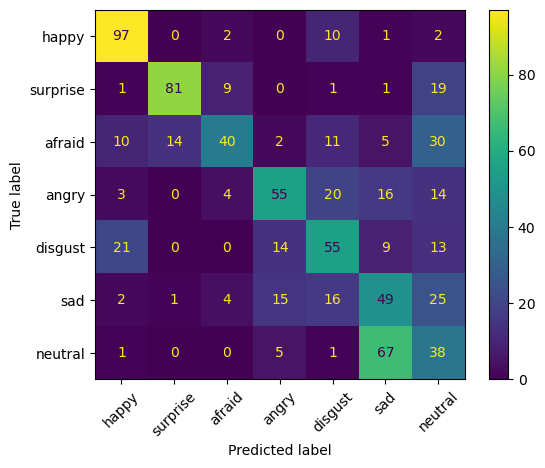

TEST acc 0.566 | bal-acc 0.566 | macro-F1 0.557


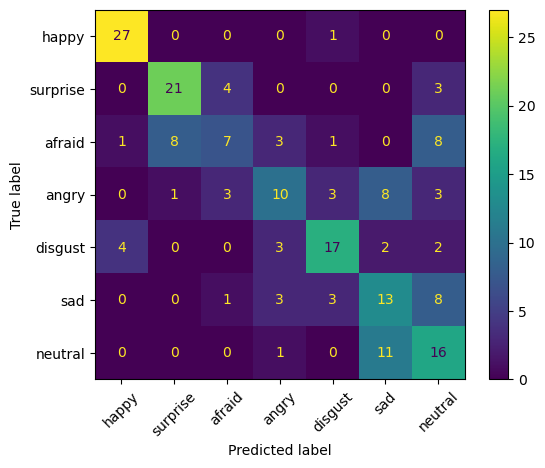

In [ ]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

# 1) Membership functions: breakpoints from TRAIN percentiles only
# IMPORTANT: We use only training data percentiles to define the breakpoints.
# This prevents data leakage - we should not use test data to design our classifier.
# For each feature, we compute:
# - 20th percentile (p20): boundary for "low"
# - 50th percentile (p50): median, used as peak for "medium" and boundary between low/high
# - 70th percentile (p70): boundary where "vhigh" starts rising
# - 80th percentile (p80): boundary where "high" reaches 1
# - 90th percentile (p90): boundary where "vhigh" reaches 1
BP = {f: np.percentile(train[f], [20, 50, 80, 70, 90]) for f in FEATURES}

def mu(f, term, x):
    """
    Compute the membership degree of value x in the fuzzy set 'term' for feature 'f'.
    Returns a value between 0 (not a member) and 1 (fully a member).
    
    Four fuzzy sets are defined per feature:
    - "low":   membership = 1 when x <= p20, decreases to 0 at p50
    - "medium": triangular function peaking at p50, zero at p20 and p80
    - "high":  membership = 0 when x <= p50, increases to 1 at p80
    - "vhigh": membership = 0 when x <= p70, increases to 1 at p90
    """
    p20, p50, p80, p70, p90 = BP[f] # Unpack the percentile breakpoints for this feature
    if term == "low":                    # "Low" is 1 below p20, falls to 0 at p50
        return np.clip((p50 - x) / (p50 - p20), 0, 1)
    if term == "high":                   # "High" is 0 below p50, rises to 1 at p80
        return np.clip((x - p50) / (p80 - p50), 0, 1)
    if term == "vhigh":                  # "vhigh" 0 below p70, rises to 1 at p90
        return np.clip((x - p70) / (p90 - p70), 0, 1)
    # "medium" is a triangular membership function peaking at p50, zero at p20 and p80
    return np.clip(np.minimum((x - p20) / (p50 - p20),
                              (p80 - x) / (p80 - p50)), 0, 1)

# 2) Rule base: IF all (feature is term) THEN emotion (AND = min)
# Each rule is a list of (feature, term) conditions.
# The AND operator is implemented using the minimum (min) of the membership values.
# These rules are designed to be human-interpretable and reflect common psychological
# interpretations of facial expressions.
RULES = {
    # Happy: very high smile + very wide mouth
    "happy":    [("smile","vhigh"), ("mouth_width","vhigh")],

    # Surprise: high mouth opening (jaw dropped), high eye opening (wide eyes),
    # high eyebrow height (raised brows), low mouth width (mouth not stretched wide)
    "surprise": [("mouth_opening","high"), ("eye_opening","high"),
                 ("eyebrow_height","high"), ("mouth_width","low")],

    # Afraid: high eye opening (wide eyes), medium mouth opening, medium mouth width
    "afraid":   [("eye_opening","high"), ("mouth_opening","medium"),
                 ("mouth_width","medium")],

    # Angry: low eyebrow height (brows lowered), low brow gap (brows furrowed together),
    # low mouth opening (mouth closed/pressed)
    "angry":    [("eyebrow_height","low"), ("brow_gap","low"),
                 ("mouth_opening","low")],

    # Disgust: low eye opening (squinted eyes), medium mouth opening
    "disgust":  [("eye_opening","low"), ("mouth_opening","medium")],

    # Sad: low mouth opening (mouth closed), medium eye opening
    "sad":      [("mouth_opening","low"), ("eye_opening","medium")],
    
    # Neutral: low mouth opening (closed mouth), high eye opening (normal open eyes)
    "neutral":  [("mouth_opening","low"), ("eye_opening","high")],
}
CLASSES = list(RULES) # List of emotion classes in the order defined above

# 3) Inference: rule strength = min of memberships; class = rule with max strength
def firing(row):
    """
    Compute the firing strength of each rule for a single sample.
    The firing strength of a rule is the minimum of the membership values
    of all its conditions (this implements the AND operator).
    """
    return {c: min(mu(f, t, row[f]) for f, t in conds)
            for c, conds in RULES.items()}

def predict(dfx):
    """
    Predict emotion for each row in the DataFrame.
    The prediction is the class with the highest firing strength.
    If no rule fires (all strengths are 0), we default to "neutral".
    """
    out = []
    for _, r in dfx.iterrows():
        s = firing(r) # Get firing strength for each rule/class
        # Choose the class with max firing strength, or "neutral" if no rule fires
        out.append(max(s, key=s.get) if max(s.values()) > 0 else "neutral")
    return np.array(out)

# 4) Evaluation
def evaluate(dfx, title=""):
    """
    Evaluate the fuzzy classifier on a dataset.
    Prints accuracy, balanced accuracy, and macro-F1, and displays a confusion matrix.
    """
    y, p = dfx.emotion.values, predict(dfx) # True labels and predictions
    print(title, "acc %.3f | bal-acc %.3f | macro-F1 %.3f" % (
        accuracy_score(y, p), balanced_accuracy_score(y, p),
        f1_score(y, p, average="macro")))
    # Plot confusion matrix to show which emotions are confused with each other
    ConfusionMatrixDisplay(confusion_matrix(y, p, labels=CLASSES),
                           display_labels=CLASSES).plot(xticks_rotation=45)
    plt.show()

# Evaluate on training set (to check if the rules capture the training data well)
evaluate(train, "TRAIN")

# Evaluate on test set (this is the important result - how well do the rules generalize?)
evaluate(feat[feat.split == "test"], "TEST")

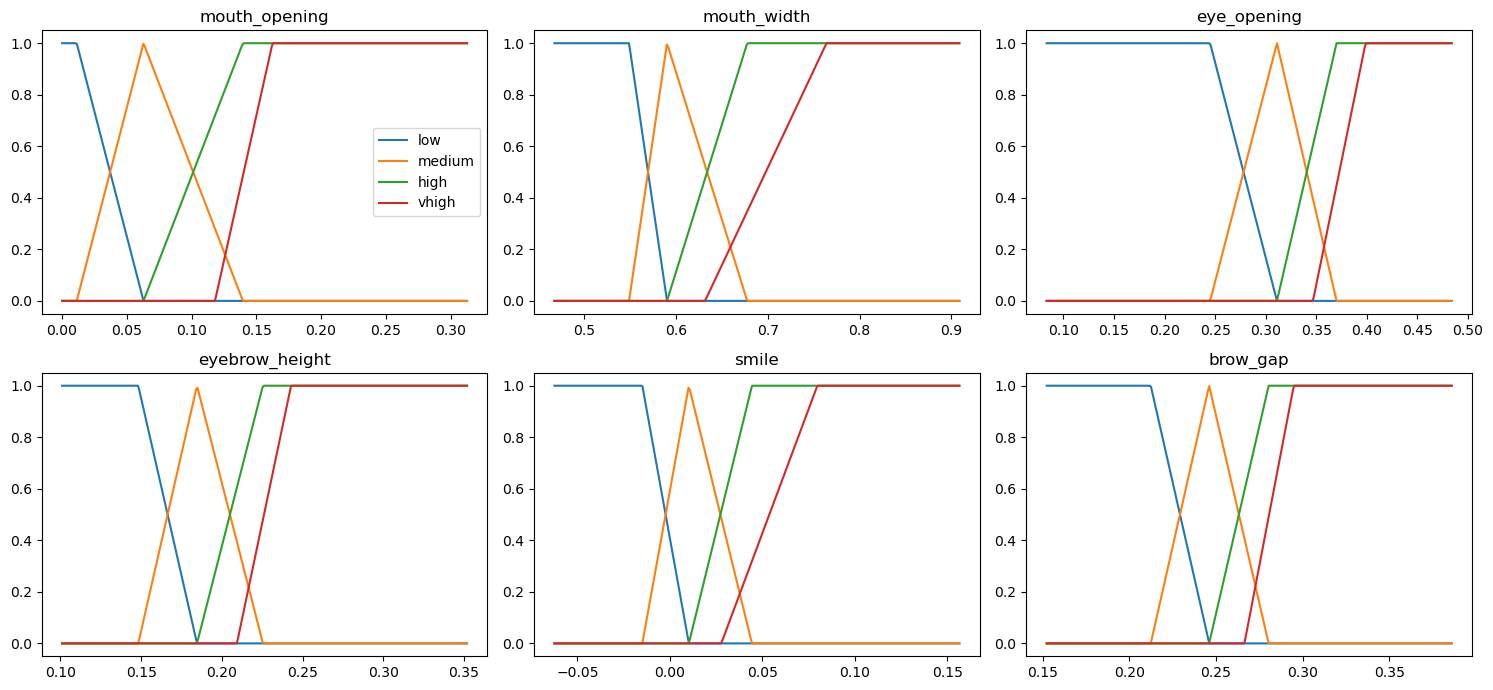

In [ ]:
import json # For saving the rules and breakpoints as JSON
os.makedirs("figures", exist_ok=True) # Create figures directory if it doesn't exist

# --- Visualize the membership functions ---
# This plot shows the shape of each fuzzy set (low, medium, high, vhigh) for each feature.
# These are the functions that convert a raw feature value (e.g., smile = 0.12) 
# into a membership degree (e.g., "smile is 0.8 high").
# Understanding these plots helps explain WHY the classifier makes certain decisions.

fig, axes = plt.subplots(2, 3, figsize=(15, 7)) # 2x3 grid of subplots (one per feature)
for ax, f in zip(axes.ravel(), FEATURES): # Iterate over each feature
    # Create a range of x values spanning the min to max of the training data for this feature
    xs = np.linspace(train[f].min(), train[f].max(), 300)

    # Plot each membership function (low, medium, high, vhigh) on the same axes
    for term in ["low", "medium", "high", "vhigh"]:
        ax.plot(xs, mu(f, term, xs), label=term)
    ax.set_title(f)  # Set the feature name as the title
    ax.set_ylim(-0.05, 1.05)  # Set y-axis limits to accommodate membership values [0, 1]
axes[0, 0].legend()  # Add a legend to the first subplot
plt.tight_layout()  # Adjust spacing to prevent overlap
plt.savefig("figures/membership_functions.pdf")  # Save the figure as PDF
plt.show()  # Display the figure

# Save the frozen rules and breakpoints
# We save the rules and breakpoints to a JSON file for reproducibility.
# This allows anyone to reconstruct the exact same fuzzy classifier without re-running the notebook.
# The breakpoints are specific to the training data percentiles, so saving them is important.
json.dump({"rules": RULES, "breakpoints": {f: BP[f].tolist() for f in FEATURES}},
          open("auxFiles/fuzzy_rules_frozen.json", "w"), indent=2)